In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet(
    "../data/processed/analytical_sample.parquet"
)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

Dataset shape: (1913000, 22)
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


In [2]:
daily_sales = (
    df.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)
# Smooth short-term fluctuations
daily_sales["sales_28d_avg"] = (
    daily_sales["sales"]
    .rolling(window=28)
    .mean()
)
daily_sales.head()

,date,sales,sales_28d_avg
0,2011-01-29,849,NaN
1,2011-01-30,771,NaN
2,2011-01-31,643,NaN
3,2011-02-01,602,NaN
4,2011-02-02,427,NaN


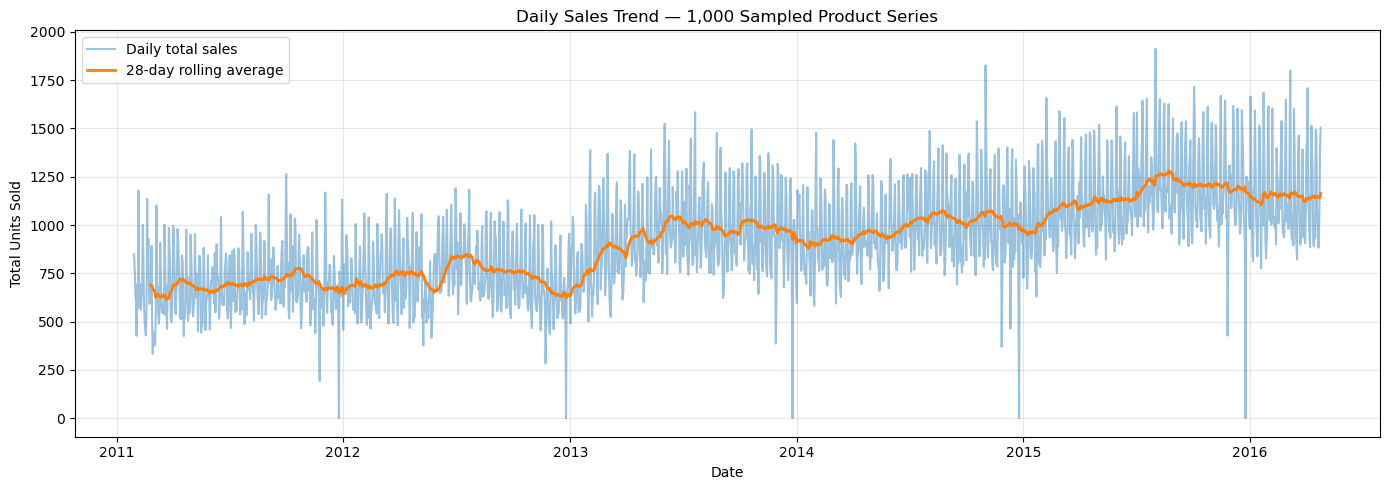

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    label="Daily total sales",
    alpha=0.45
)

plt.plot(
    daily_sales["date"],
    daily_sales["sales_28d_avg"],
    label="28-day rolling average",
    linewidth=2
)

plt.title("Daily Sales Trend — 1,000 Sampled Product Series")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
zero_sales_dates = (
    daily_sales.loc[
        daily_sales["sales"] == 0,
        "date"
    ]
)

print("Number of dates with zero total sales:",
      len(zero_sales_dates))

print("\nDates with zero total sales:")
print(zero_sales_dates.tolist())

Number of dates with zero total sales: 5

Dates with zero total sales:
[Timestamp('2011-12-25 00:00:00'), Timestamp('2012-12-25 00:00:00'), Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00')]


In [5]:
zero_date_check = (
    df[df["date"].isin(zero_sales_dates)]
    .groupby("date")
    .agg(
        total_sales=("sales", "sum"),
        observations=("sales", "size"),
        positive_sales_series=(
            "sales",
            lambda s: (s > 0).sum()
        )
    )
)

print(zero_date_check)

            total_sales  observations  positive_sales_series
date                                                        
2011-12-25            0          1000                      0
2012-12-25            0          1000                      0
2013-12-25            0          1000                      0
2014-12-25            0          1000                      0
2015-12-25            0          1000                      0


In [6]:
weekday_order = [
    "Saturday",
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]

daily_weekday = (
    df.groupby(["date", "weekday"], as_index=False)
    .agg(daily_sales=("sales", "sum"))
)

weekday_sales = (
    daily_weekday
    .groupby("weekday")["daily_sales"]
    .mean()
    .reindex(weekday_order)
)

print(weekday_sales)

weekday
Saturday     1161.273723
Sunday       1134.514599
Monday        887.732601
Tuesday       796.904762
Wednesday     772.029304
Thursday      774.007326
Friday        912.311355
Name: daily_sales, dtype: float64


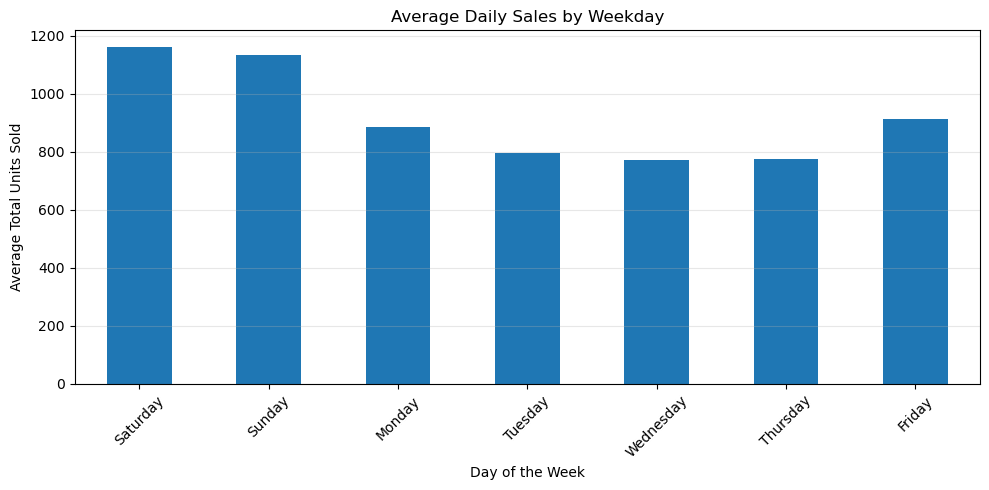

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Day of the Week")
plt.ylabel("Average Total Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Extract the calendar month from each date
daily_sales["month"] = daily_sales["date"].dt.month

# Calculate average daily sales for each month across all years
monthly_sales = (
    daily_sales.groupby("month")["sales"]
    .mean()
    .reindex(range(1, 13))
)

print(monthly_sales.round(2))

month
1     898.94
2     905.11
3     900.79
4     938.67
5     874.14
6     944.53
7     948.18
8     966.23
9     931.86
10    947.48
11    904.81
12    884.14
Name: sales, dtype: float64


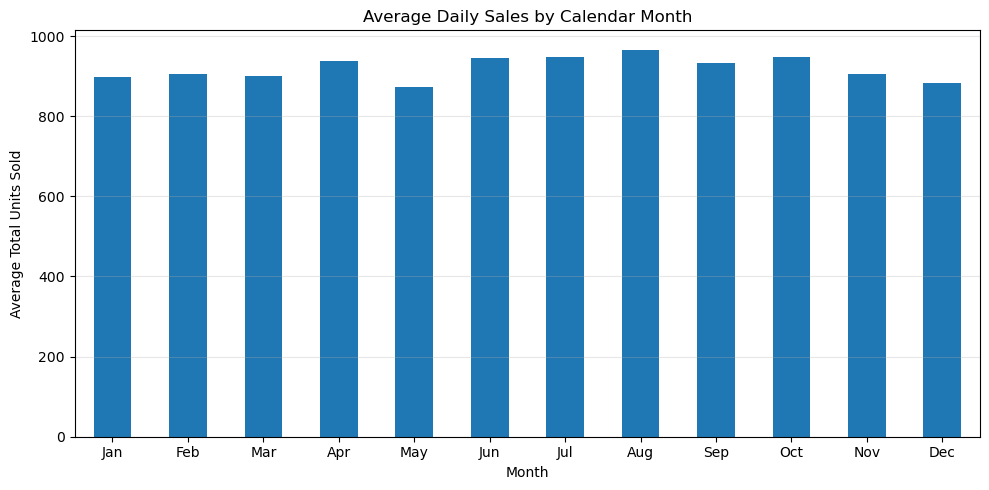

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="bar")

plt.title("Average Daily Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Total Units Sold")
plt.xticks(
    ticks=range(12),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ],
    rotation=0
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
christmas_check = (
    df.loc[
        df["date"].isin(zero_sales_dates),
        [
            "date",
            "weekday",
            "event_name_1",
            "event_type_1",
            "event_name_2",
            "event_type_2"
        ]
    ]
    .drop_duplicates()
    .sort_values("date")
)

display(christmas_check)

,date,weekday,event_name_1,event_type_1,event_name_2,event_type_2
330000,2011-12-25,Sunday,Christmas,National,None,None
696000,2012-12-25,Tuesday,Christmas,National,None,None
1061000,2013-12-25,Wednesday,Christmas,National,None,None
1426000,2014-12-25,Thursday,Christmas,National,None,None
1791000,2015-12-25,Friday,Christmas,National,None,None


In [11]:
#Sales distribution
import pandas as pd

# Count observations for each daily sales quantity
sales_counts = df["sales"].value_counts().sort_index()
# Group sales into readable categories: 0, 1, ..., 10, and 11+
sales_distribution = pd.concat([
    sales_counts.loc[sales_counts.index <= 10],
    pd.Series(
        {11: sales_counts.loc[sales_counts.index > 10].sum()}
    )
]).sort_index()
sales_distribution.index = [
    str(value) if value <= 10 else "11+"
    for value in sales_distribution.index
]
# Convert counts to percentages
sales_percentage = (
    sales_distribution / len(df) * 100
) 
print("Sales distribution (% of all observations):")
print(sales_percentage.round(2))

Sales distribution (% of all observations):
0      67.21
1      14.74
2       7.52
3       3.81
4       2.16
5       1.24
6       0.82
7       0.52
8       0.39
9       0.29
10      0.22
11+     1.07
dtype: float64


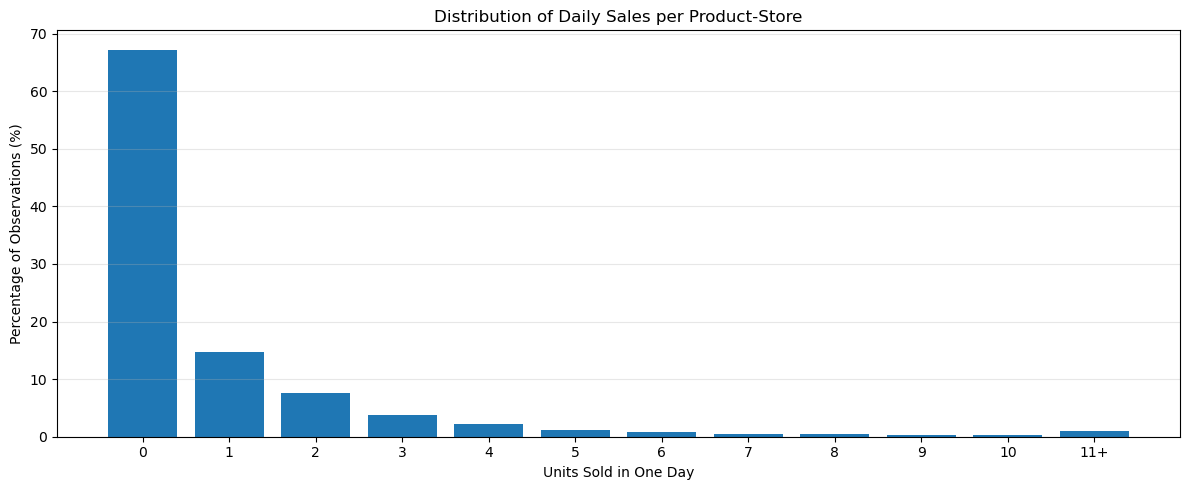

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    sales_percentage.index,
    sales_percentage.values
)

plt.title("Distribution of Daily Sales per Product-Store")
plt.xlabel("Units Sold in One Day")
plt.ylabel("Percentage of Observations (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

- Zero sales dominate :approx 67.2% of obseration have zero sales
- Low daily demand is common: One or two units account for a large proportion of observation
- Demand is highly right skewed